# 02 · Pruebas de hipótesis, potencia y sus trampas

**Objetivo:** entender qué es (y qué no es) un p-valor, dimensionar un experimento, y
reproducir por simulación los dos errores más caros de los A/B tests en la industria:
**mirar los resultados antes de tiempo** y **probar muchas métricas a la vez**.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
from applied_stats import (
    benjamini_hochberg,
    holm,
    power_two_proportions,
    sample_size_two_proportions,
    two_proportion_ztest,
)

## 1. Un test, paso a paso

Control: 10.0 % de conversión sobre 5000 usuarios; tratamiento: 11.2 % sobre 5000.

In [2]:
res = two_proportion_ztest(500, 5000, 560, 5000)
print(f"diferencia = {res.diff:.4f}, IC 95 % = ({res.ci[0]:.4f}, {res.ci[1]:.4f})")
print(f"z = {res.statistic:.3f}, p = {res.pvalue:.4f}")

diferencia = 0.0120, IC 95 % = (-0.0001, 0.0241)
z = 1.949, p = 0.0513


p = 0.051: ¿“no hay efecto”? **No.** El intervalo dice que los efectos compatibles con los
datos van de ~0 a +2.4 puntos: el experimento no tuvo potencia para distinguirlos de cero.
“No significativo” es ausencia de evidencia, no evidencia de ausencia.

**Qué es el p-valor:** $P(\text{estadístico al menos tan extremo} \mid H_0)$.
**Qué no es:** la probabilidad de que $H_0$ sea cierta, ni la de que el efecto sea real.

## 2. La distribución de los p-valores

Bajo $H_0$ el p-valor es **uniforme** en [0, 1]: por eso rechazar si $p < 0.05$ da 5 % de
falsos positivos. Bajo $H_1$ se concentra cerca de 0, tanto más cuanto mayor la potencia.
(Simulación vectorizada con `scipy.stats.ttest_ind`; los tests del módulo verifican que
`applied_stats.welch_ttest` coincide con scipy.)

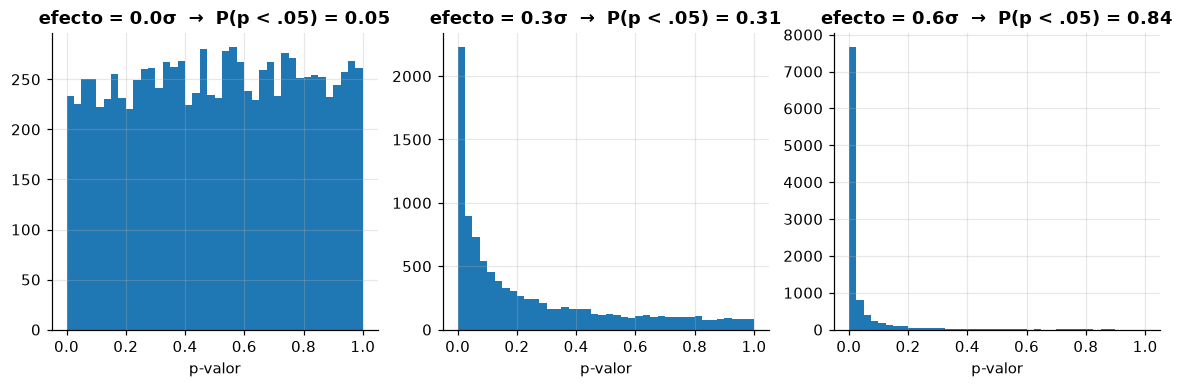

In [3]:
reps, n = 10_000, 50
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, effect in zip(axes, [0.0, 0.3, 0.6], strict=True):
    a = rng.normal(0, 1, (reps, n))
    b = rng.normal(effect, 1, (reps, n))
    p = stats.ttest_ind(b, a, axis=1, equal_var=False).pvalue
    ax.hist(p, bins=40, range=(0, 1), color="C0")
    ax.set_title(f"efecto = {effect}σ  →  P(p < .05) = {np.mean(p < 0.05):.2f}")
    ax.set_xlabel("p-valor")

## 3. Potencia y tamaño de muestra

$n \propto 1/\Delta^2$: detectar la mitad del efecto cuesta **cuatro veces** más usuarios.

In [4]:
base = 0.10
print(f"{'lift relativo':>14} {'Δ absoluto':>11} {'n por grupo':>12}")
for lift in [0.20, 0.10, 0.05, 0.02]:
    p2 = base * (1 + lift)
    print(f"{lift:>14.0%} {p2 - base:>11.4f} {sample_size_two_proportions(base, p2):>12,}")

 lift relativo  Δ absoluto  n por grupo
           20%      0.0200        3,841
           10%      0.0100       14,751
            5%      0.0050       57,763
            2%      0.0020      356,335


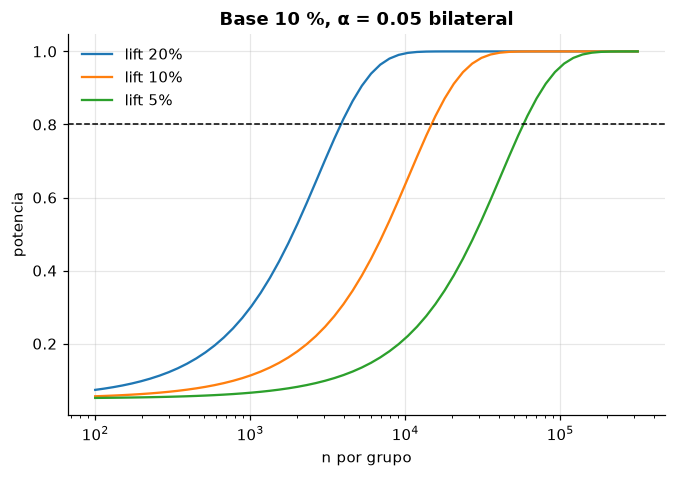

In [5]:
ns = np.logspace(2, 5.5, 60).astype(int)
fig, ax = plt.subplots()
for lift in [0.20, 0.10, 0.05]:
    ax.plot(
        ns,
        [power_two_proportions(base, base * (1 + lift), n) for n in ns],
        label=f"lift {lift:.0%}",
    )
ax.axhline(0.8, color="k", ls="--", lw=1)
ax.set_xscale("log")
ax.set_xlabel("n por grupo")
ax.set_ylabel("potencia")
ax.set_title("Base 10 %, α = 0.05 bilateral")
ax.legend();

## 4. Trampa 1: mirar antes de tiempo (*peeking*)

Test A/A (sin efecto real), 20 000 usuarios por grupo. Se revisa el p-valor cada 1000 usuarios
y se detiene en cuanto $p < 0.05$. Cada mirada es otra oportunidad de un falso positivo.

In [6]:
reps, n_max, step, p0 = 4000, 20_000, 1000, 0.10
looks = np.arange(step, n_max + 1, step)
ca = np.cumsum(rng.random((reps, n_max)) < p0, axis=1)[:, looks - 1]
cb = np.cumsum(rng.random((reps, n_max)) < p0, axis=1)[:, looks - 1]
pool = (ca + cb) / (2 * looks)
z = (cb - ca) / looks / np.sqrt(pool * (1 - pool) * 2 / looks)
p = 2 * stats.norm.sf(np.abs(z))

fpr_by_looks = [np.mean((p[:, :k] < 0.05).any(axis=1)) for k in range(1, len(looks) + 1)]
print(f"una sola mirada al final: {np.mean(p[:, -1] < 0.05):.3f}")
print(f"mirando {len(looks)} veces:      {fpr_by_looks[-1]:.3f}")

una sola mirada al final: 0.045
mirando 20 veces:      0.237


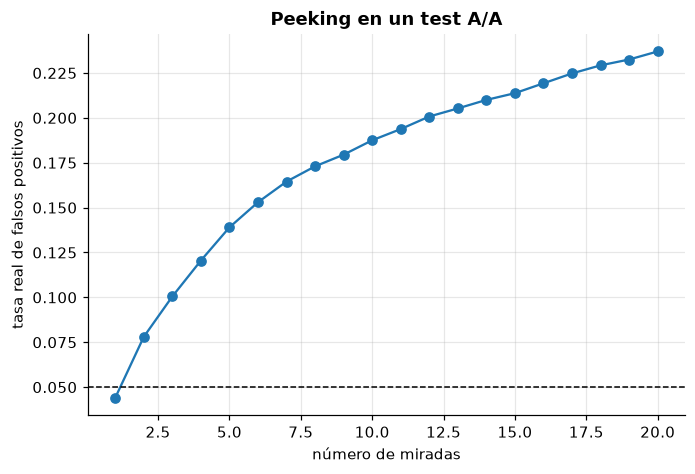

In [7]:
fig, ax = plt.subplots()
ax.plot(range(1, len(looks) + 1), fpr_by_looks, "o-")
ax.axhline(0.05, color="k", ls="--", lw=1)
ax.set_xlabel("número de miradas")
ax.set_ylabel("tasa real de falsos positivos")
ax.set_title("Peeking en un test A/A");

Soluciones: fijar $n$ de antemano (análisis de potencia) y mirar una vez; o usar métodos
secuenciales diseñados para ello (*alpha spending* de O'Brien–Fleming, tests always-valid / mSPRT).

## 5. Trampa 2: muchas métricas

Experimento A/A con 20 métricas independientes: $P(\geq 1 \text{ significativa}) = 1 - 0.95^{20} \approx 64\%$.

In [8]:
reps, m = 5000, 20
pvals = rng.uniform(size=(reps, m))  # bajo H₀ los p-valores son U(0, 1)
for name, adjust in [("sin corrección", lambda p: p), ("Holm", holm), ("BH", benjamini_hochberg)]:
    fwer = np.mean([np.any(adjust(row) < 0.05) for row in pvals])
    print(f"{name:>15}: P(≥ 1 falso positivo) = {fwer:.3f}")

 sin corrección: P(≥ 1 falso positivo) = 0.650
           Holm: P(≥ 1 falso positivo) = 0.052
             BH: P(≥ 1 falso positivo) = 0.052


Con efectos reales mezclados, BH conserva más potencia que Holm a cambio de controlar
la *proporción* de falsos descubrimientos y no la probabilidad de alguno.

## Para llevar

- Fijar métrica principal, $n$ y regla de decisión **antes** de ver datos (preregistro).
- El p-valor bajo $H_0$ es uniforme; cada mirada o métrica extra es otro boleto de lotería.
- Holm para pocas métricas confirmatorias; BH para exploración con muchas.